# How hot will the hottest day get?

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/RiskThinking/crc-docs/blob/main/notebooks/how_hot_will_it_get.ipynb)

**The question:** *"Every summer has one hottest day. How hot will that day get where I live, today and in the future?"*

We answer it three times, each with a better data source, using the same open
toolkit, [crc-sdk](https://github.com/RiskThinking/crc-sdk):

| | Data | What it can tell you |
|---|---|---|
| **A** | A public weather station (NOAA GHCNh) | What already happened at one spot |
| **B** | **CRC Open**: free, ready-made climate curves | What could happen in 2025–2100 under a high-emissions future (SSP5-8.5; [other futures on request](mailto:opensource@riskthinking.ai)) |
| **C** | **CDT**, Riskthinking.AI's Climate Digital Twin (enterprise) | Every emissions future, a matching historical baseline and financial impact |

You can run this on Colab with **Runtime → Run all**. No account needed for A and B.
Change `CITY` in the setup cell to try another place.

## Setup

In [1]:
#@title Install packages (Colab) and choose a city
import importlib.util
import os
import subprocess
import sys

IN_COLAB = importlib.util.find_spec("google.colab") is not None
if IN_COLAB or importlib.util.find_spec("crc_sdk") is None:
    subprocess.check_call([
        sys.executable, "-m", "pip", "install", "--quiet",
        "crc-sdk[geometry]>=0.11.1,<1", "plotly>=6,<7", "velo-sdk",
    ])

# Any city works: give a name and coordinates. The nearest weather station is found for you.
CITY = {"name": "Phoenix, Arizona", "latitude": 33.4278, "longitude": -112.0037}

# Small, quick runs for continuous integration; the same code runs either way.
CI = os.environ.get("CRC_DOCS_CI") == "1"
STATION_YEARS = (2005, 2024) if CI else (1995, 2024)
HORIZONS = (2025, 2050, 2080)

In [2]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import plotly.graph_objects as go
import plotly.io as pio
import pyarrow as pa
import pyarrow.parquet as pq

from crc_sdk.workflows import BlockExtremaPolicy, HazardDataset, curve_parameters_from_row

# Interactive charts when you run it; saved images so GitHub can show them too.
STATIC_PREVIEW = os.environ.get("CRC_NOTEBOOK_STATIC_PREVIEW") == "1"
pio.renderers.default = (
    "colab" if IN_COLAB else "plotly_mimetype+png" if STATIC_PREVIEW else "plotly_mimetype"
)
pio.templates.default = "plotly_white"

DATA = Path("data") / "how_hot"
DATA.mkdir(parents=True, exist_ok=True)

# One colour per idea, used the same way in every chart.
PAST = "#52514e"                                   # what was measured
FUTURE = {2025: "#f5b08f", 2050: "#eb6834", 2080: "#9c3a12"}  # light to dark = later
CDT_COLORS = {"historic": "#52514e", "ssp126": "#2a78d6", "ssp245": "#1baf7a", "ssp585": "#eb6834"}
FONT = dict(family="Inter, Helvetica, Arial, sans-serif", size=14)


def kelvin_to_celsius(values):
    return np.asarray(values, dtype=float) - 273.15


def curve_values(distribution, return_periods):
    """Evaluate a curve at return periods (years)."""
    return np.asarray(distribution.quantiles((1 - 1 / np.asarray(return_periods)).tolist()), dtype=float)


def layout(fig, title, **kwargs):
    fig.update_layout(title=dict(text=title, x=0.01), font=FONT, height=430,
                      margin=dict(l=70, r=30, t=70, b=60), **kwargs)
    return fig

## A. Ask the thermometer

Weather stations have measured temperature for decades. NOAA's
[GHCNh](https://www.ncei.noaa.gov/products/global-historical-climatology-network-hourly)
publishes hourly readings for thousands of them, free (CC0). We take the
**hottest reading of each year** at the station nearest to `CITY`.

In [3]:
search = 0.25  # degrees around the city, roughly 25 km
station_plan = (
    HazardDataset.ghcnh("temperature_max")
    .for_area((CITY["longitude"] - search, CITY["latitude"] - search,
               CITY["longitude"] + search, CITY["latitude"] + search))
    .years(*STATION_YEARS)
    .cache(DATA / "ghcnh", mode="reuse")
)
stations = station_plan.stations().to_pandas()
stations["distance_km"] = 111 * np.hypot(
    stations["latitude"] - CITY["latitude"],
    (stations["longitude"] - CITY["longitude"]) * np.cos(np.radians(CITY["latitude"])),
)
# Try the nearest stations until one has enough complete years to fit a curve.
station, annual, station_curve = None, None, None
for _, candidate in stations.sort_values("distance_km").head(3).iterrows():
    station_plan = (
        HazardDataset.ghcnh("temperature_max")
        .for_stations([candidate["station"]])
        .years(*STATION_YEARS)
        .quality(minimum_hour_fraction=0.75, minimum_day_fraction=0.9)
        .cache(DATA / "ghcnh", mode="reuse")
        .canonicalize(policy=BlockExtremaPolicy.curated(minimum_years=15))
    )
    curve_path = DATA / f"station-{candidate['station']}.parquet"
    try:
        station_plan.materialize(curve_path)
    except (ValueError, LookupError):
        continue
    curve_rows = pq.read_table(curve_path).to_pylist()
    if curve_rows and curve_rows[0]["curve_kind"] != "no_data":
        station = candidate
        station_curve = curve_parameters_from_row(curve_rows[0]).to_distribution()
        station_plan.write_annual_extremes(DATA / "annual.parquet")
        annual = pq.read_table(DATA / "annual.parquet").to_pandas()
        annual = annual[annual["complete"]].dropna(subset=["value"])
        break

if station is None:
    print("No nearby station has enough complete years; part A is skipped for this city.")
else:
    hottest = annual.loc[annual["value"].idxmax()]
    print(f"Station: {station['name']} ({station['station']}), {station['distance_km']:.1f} km away")
    print(f"{len(annual)} complete years, hottest reading {hottest['value']:.1f} °C in {int(hottest['year'])}")

Station: PHOENIX AP (USW00023183), 0.0 km away
25 complete years, hottest reading 48.3 °C in 2017


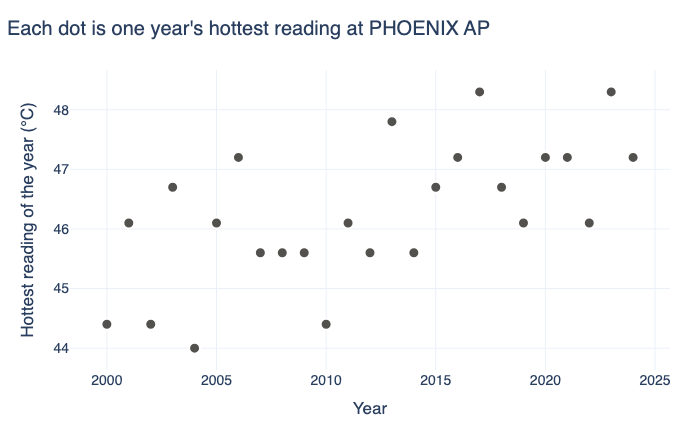

In [4]:
def show_station_years():
    fig = go.Figure(go.Scatter(
        x=annual["year"], y=annual["value"], mode="markers",
        marker=dict(size=11, color=PAST, line=dict(width=2, color="white")),
        hovertemplate="%{x}: hottest reading %{y:.1f} °C<extra></extra>",
    ))
    layout(fig, f"Each dot is one year's hottest reading at {station['name']}",
           xaxis_title="Year", yaxis_title="Hottest reading of the year (°C)", showlegend=False)
    fig.show()


if station is not None:
    show_station_years()

> 💡 **Key idea: the "1-in-10-year" day.** Imagine every summer rolls a
> 10-sided die. A **1-in-10-year hottest day** is as hot as the summer that rolls
> a 10: it happens about once a decade on average, and has a 10% chance in any
> single year. Return periods are just this die with more sides.

The dots alone only cover the years we have. To talk about the 1-in-50 or
1-in-100-year day, crc-sdk **fits a curve** through them (a GEV distribution,
the standard choice for yearly extremes). Below, the dots are sorted from mildest
to hottest and placed at the return period they represent; the line is the fitted curve.
(Readings are rounded, so some years tie at the same temperature.)

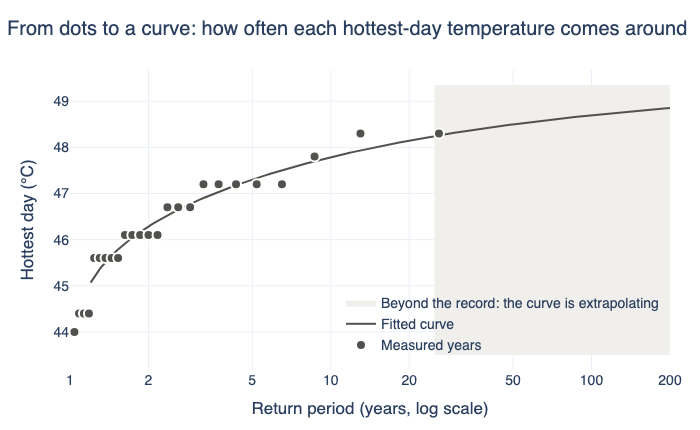

,return period,hottest day (°C)
0,2,46.3
1,10,47.8
2,50,48.5
3,100,48.7


In [5]:
rp_grid = np.geomspace(1.2, 200, 200)


def show_station_curve():
    values = np.sort(annual["value"].to_numpy())
    plotting_rp = (len(values) + 1) / np.arange(len(values), 0, -1)  # Weibull plotting positions
    record_years = len(values)
    low, high = values.min() - 0.5, curve_values(station_curve, [200])[0] + 0.5

    fig = go.Figure()
    fig.add_trace(go.Scatter(x=[record_years, 200, 200, record_years], y=[low, low, high, high], fill="toself",
                             fillcolor="#f0efec", line_width=0, mode="lines", hoverinfo="skip",
                             name="Beyond the record: the curve is extrapolating"))
    fig.add_trace(go.Scatter(x=rp_grid, y=curve_values(station_curve, rp_grid), mode="lines",
                             name="Fitted curve", line=dict(color=PAST, width=2)))
    fig.add_trace(go.Scatter(x=plotting_rp, y=values, mode="markers", name="Measured years",
                             marker=dict(size=10, color=PAST, line=dict(width=2, color="white")),
                             hovertemplate="%{y:.1f} °C, about 1-in-%{x:.0f} years<extra></extra>"))
    layout(fig, "From dots to a curve: how often each hottest-day temperature comes around",
           xaxis=dict(type="log", title="Return period (years, log scale)",
                      tickvals=[1, 2, 5, 10, 20, 50, 100, 200], range=[0, np.log10(200)]),
           yaxis_title="Hottest day (°C)",
           legend=dict(x=0.99, y=0.03, xanchor="right", yanchor="bottom", bgcolor="rgba(0,0,0,0)"))
    fig.show()
    table = pd.DataFrame({"return period": [2, 10, 50, 100]})
    table["hottest day (°C)"] = curve_values(station_curve, table["return period"]).round(1)
    return table


show_station_curve() if station is not None else None

**What A tells us, and what it can't:**

- ✅ Real measurements, free and transparent.
- ❌ **Only the past.** A thermometer can't measure 2050.
- ❌ **One spot.** It describes the airport, not your whole neighbourhood.
- ❌ **Short record.** With about 30 years, anything rarer than 1-in-30 is extrapolated (shaded area).

## B. Ask CRC Open

[CRC Open](https://github.com/RiskThinking/crc-sdk/blob/main/docs/sources/crc-open.md)
is a free public release of ready-made climate curves for 63 hazards worldwide, from
2025 to 2100, built from bias-corrected climate models
([CC BY-NC 4.0](https://creativecommons.org/licenses/by-nc/4.0/)). There is nothing
to fit: crc-sdk downloads only the small area you ask for, checks its checksum,
and hands you the curve.

This public release covers one high-emissions future, SSP5-8.5. Lower-emissions
futures are available too: [ask the open-source team](mailto:opensource@riskthinking.ai).

In [6]:
crc_plan = (
    HazardDataset.crc_open()
    .for_area((CITY["longitude"] - 0.05, CITY["latitude"] - 0.05,
               CITY["longitude"] + 0.05, CITY["latitude"] + 0.05))
    .hazards(["tx_max"])
    .horizons(list(HORIZONS))
    .cache(DATA / "crc-open", mode="reuse")
)
selection = crc_plan.resolve()
print(f"Downloading {selection.total_bytes / 1e6:.0f} MB once (cached afterwards)")

city = pa.table({"asset_id": [CITY["name"]], "longitude": [CITY["longitude"]], "latitude": [CITY["latitude"]]})
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    crc_plan.for_assets(city).return_periods([2]).write_parquet(DATA / "city_tx_max.parquet")
    crc_curves = crc_plan.materialize(DATA / "tx_max.parquet")

matched_cell = pq.read_table(DATA / "city_tx_max.parquet").column("cell_index")[0].as_py()
rows = [row for row in pq.read_table(DATA / "tx_max.parquet").to_pylist() if row["cell_index"] == matched_cell]
future = {row["horizon"]: curve_parameters_from_row(row).to_distribution() for row in rows}
print("Horizons:", sorted(future), "| scenario:", rows[0]["pathway"])

Horizons: [2025, 2050, 2080] | scenario: ssp585


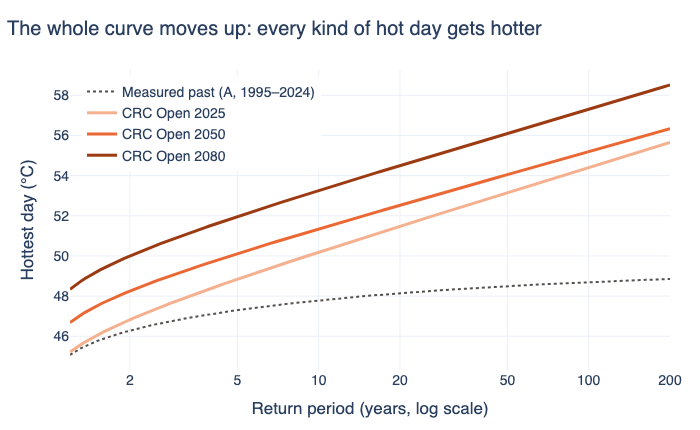

In [7]:
fig = go.Figure()
if station is not None:
    fig.add_trace(go.Scatter(x=rp_grid, y=curve_values(station_curve, rp_grid), mode="lines",
                         name=f"Measured past (A, {STATION_YEARS[0]}–{STATION_YEARS[1]})",
                         line=dict(color=PAST, width=2, dash="dot")))
for horizon in HORIZONS:
    fig.add_trace(go.Scatter(x=rp_grid, y=kelvin_to_celsius(curve_values(future[horizon], rp_grid)),
                             mode="lines", name=f"CRC Open {horizon}", line=dict(color=FUTURE[horizon], width=3)))
layout(fig, "The whole curve moves up: every kind of hot day gets hotter",
       xaxis=dict(type="log", title="Return period (years, log scale)", tickvals=[1, 2, 5, 10, 20, 50, 100, 200]),
       yaxis_title="Hottest day (°C)", legend=dict(x=0.02, y=0.98))
fig.show()

> 💡 **Key idea: two honest sources won't match exactly, and that's expected.**
> Look at the dotted line (thermometer) and the 2025 curve. For a **typical**
> year (the left side) they agree to within about a degree. In the **rare-event tail**
> (the right side) CRC Open is hotter, for good reasons:
>
> 1. **A point vs an area.** The station is one spot; CRC Open describes a
>    hexagon of roughly 250 km² (shown on the map below).
> 2. **Many models vs one history.** CRC Open pools many climate models, so
>    its tail includes the "what if" years that our 30 real summers never rolled.
> 3. **Hourly sampling.** The station's hottest *hourly* reading slightly
>    understates the true daily peak.
>
> Knowing *why* sources differ is the point: crc-sdk keeps each curve's units,
> source and coverage attached, so you can always check.

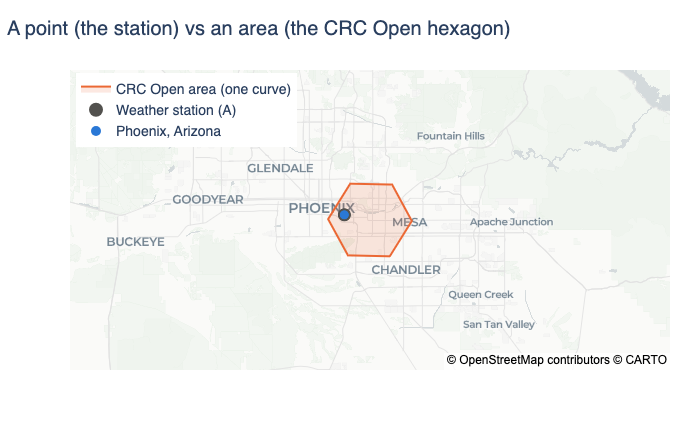

In [8]:
from crc_sdk.geometry import cell_polygon

hexagon = cell_polygon(matched_cell)
lon, lat = hexagon.exterior.xy
fig = go.Figure()
fig.add_trace(go.Scattermap(lon=list(lon), lat=list(lat), mode="lines", fill="toself", name="CRC Open area (one curve)",
                            line=dict(color=FUTURE[2050], width=2), fillcolor="rgba(235,104,52,0.15)"))
if station is not None:
    fig.add_trace(go.Scattermap(lon=[station["longitude"]], lat=[station["latitude"]], mode="markers",
                                name="Weather station (A)", marker=dict(size=14, color=PAST)))
fig.add_trace(go.Scattermap(lon=[CITY["longitude"]], lat=[CITY["latitude"]], mode="markers",
                            name=CITY["name"], marker=dict(size=10, color="#2a78d6")))
fig.update_layout(map=dict(style="carto-positron", center=dict(lat=hexagon.centroid.y, lon=hexagon.centroid.x), zoom=8))
layout(fig, "A point (the station) vs an area (the CRC Open hexagon)", legend=dict(x=0.01, y=0.99))
fig.show()

### The answer, in one picture

Instead of comparing against a different source, compare CRC Open with itself:
take today's (2025) **1-in-10-year hottest day** and ask how often that same
temperature comes around later in the century.

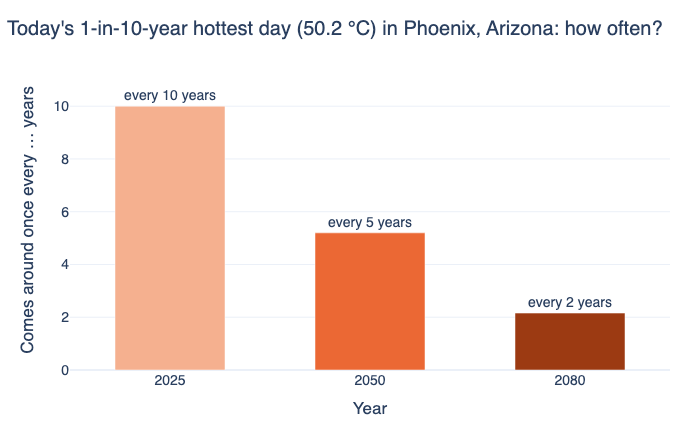

In [9]:
today_rp = 10
threshold = float(curve_values(future[2025], [today_rp])[0])
new_rp = {h: 1 / (1 - float(np.asarray(future[h].cdf([threshold]))[0])) for h in HORIZONS}

fig = go.Figure(go.Bar(
    x=[str(h) for h in HORIZONS], y=[new_rp[h] for h in HORIZONS],
    marker_color=[FUTURE[h] for h in HORIZONS], width=0.55,
    text=[f"every {new_rp[h]:.0f} years" if new_rp[h] >= 1.95 else "almost every year" for h in HORIZONS],
    textposition="outside", cliponaxis=False,
    hovertemplate="%{x}: once every %{y:.1f} years<extra></extra>",
))
layout(fig, f"Today's 1-in-{today_rp}-year hottest day ({kelvin_to_celsius(threshold):.1f} °C) in {CITY['name']}: how often?",
       yaxis=dict(title="Comes around once every … years", rangemode="tozero"), xaxis_title="Year", showlegend=False)
fig.show()

In plain words: **the kind of scorching day that now arrives about once a decade
arrives far more often later this century** under this scenario. (Neighbouring
horizons, such as 2025 and 2030, can wobble because each is estimated from a
limited sample of model years; compare horizons decades apart.)

**What B adds over A:** the future, a full curve with no fitting, and the
same format for 63 hazards worldwide (heat, rain, drought, wildfire weather, river
and coastal flood, cyclones and more).

**What B leaves out:** CRC Open covers one emissions pathway, **SSP5-8.5** (high
emissions), and has no matching historical baseline. Need other pathways for
planning or disclosure? See part C, or ask [opensource@riskthinking.ai](mailto:opensource@riskthinking.ai) about more CRC Open data.

## C. Ask CDT

**CDT** (Climate Digital Twin) is Riskthinking.AI's enterprise service. For
any location it returns the same kind of curves for **every emissions pathway**
(SSP1-2.6 to SSP5-8.5, plus warming levels), a **historical baseline** from the same
models, and the **financial impact** on buildings, plus asset, company and market-index views.

The saved results below come from a CDT run: a small table of return levels
and one chart. To run it yourself you need an API key; [start a CDT Express trial](https://velo.riskthinking.ai/cdt-express)
to get one. In Colab, store it as a secret named `RISKTHINKING_API_KEY`. Without a
key the cells explain how to get one and skip.

Prefer chatting to coding? Connect the [CDT Express MCP server](https://github.com/RiskThinking/cdt-express-mcp)
to Claude or ChatGPT and ask: *"How hot will the hottest day get in Phoenix in 2050 under each scenario?"*

In [10]:
api_key = os.environ.get("RISKTHINKING_API_KEY")
if api_key is None and IN_COLAB:
    from google.colab import userdata
    try:
        api_key = userdata.get("RISKTHINKING_API_KEY")
    except Exception:
        api_key = None

cdt = None
if api_key:
    from velo_sdk.api import APIClient

    client = APIClient(api_key=api_key)
    requests = [("historic", 2010)] + [(pathway, 2050) for pathway in ("ssp126", "ssp245", "ssp585")]
    records = []
    for pathway, horizon in requests:
        response = client.get("/v4/climate/metrics/exposure", params={
            "latitude": CITY["latitude"], "longitude": CITY["longitude"], "risk_factor": "tx_max",
            "pathway": pathway, "horizon": str(horizon), "return_periods": "2,5,10,20,50,100",
        })
        for result in response["results"]:
            if result["index_name"] != "tx_max":
                continue
            for rp, value in result["exposure_return_periods"].items():
                records.append({"pathway": pathway, "horizon": horizon, "return_period": int(rp),
                                "hottest_day_c": float(value) - 273.15})
    cdt = pd.DataFrame(records)
    display(cdt.pivot_table(index="return_period", columns="pathway", values="hottest_day_c").round(1))
else:
    print("No RISKTHINKING_API_KEY found, so section C is skipped.")
    print("Start a trial at https://velo.riskthinking.ai/cdt-express.")

pathway,historic,ssp126,ssp245,ssp585
return_period,,,,
2,45.5,47.3,47.8,48.3
5,46.6,48.5,49.5,50.0
10,47.3,49.2,50.6,51.1
20,48.0,49.7,51.6,52.2
50,48.9,50.3,53.0,53.6
100,49.5,50.7,54.1,54.7


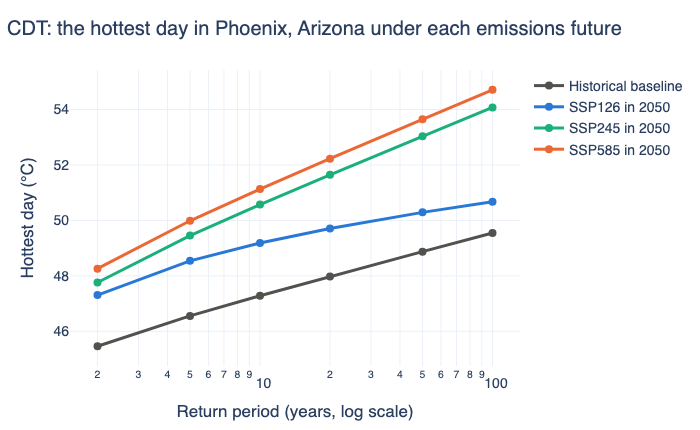

1-in-10-year hottest day: 47.3 °C in the historical baseline; in 2050 49.2 °C with low emissions (SSP1-2.6) vs 51.1 °C with high emissions (SSP5-8.5).


In [11]:
if cdt is not None:
    fig = go.Figure()
    for pathway, color in CDT_COLORS.items():
        part = cdt[cdt["pathway"] == pathway].sort_values("return_period")
        label = "Historical baseline" if pathway == "historic" else f"{pathway.upper()} in 2050"
        fig.add_trace(go.Scatter(x=part["return_period"], y=part["hottest_day_c"], mode="lines+markers",
                                 name=label, line=dict(color=color, width=3), marker=dict(size=8)))
    layout(fig, f"CDT: the hottest day in {CITY['name']} under each emissions future",
           xaxis=dict(type="log", title="Return period (years, log scale)"), yaxis_title="Hottest day (°C)")
    fig.show()
    level = cdt.set_index(["pathway", "return_period"])["hottest_day_c"]
    print(f"1-in-10-year hottest day: {level['historic', 10]:.1f} °C in the historical baseline; "
          f"in 2050 {level['ssp126', 10]:.1f} °C with low emissions (SSP1-2.6) "
          f"vs {level['ssp585', 10]:.1f} °C with high emissions (SSP5-8.5).")

**What C adds over B:**

- **Every pathway**, so you can show how much cutting emissions matters.
- **A matching historical baseline**, so "how much worse" compares like with like
  (A vs B mixed a thermometer with models).
- **Financial impact** on buildings (`/v4/climate/metrics/impact`), not only temperature.
- **Assets, companies and market indexes** already mapped, for portfolios.

## Recap

| | A. Weather station | B. CRC Open | C. CDT |
|---|---|---|---|
| Past | ✅ measured | ➖ not included | ✅ modelled baseline |
| Future | ❌ | ✅ 2025–2100 | ✅ 2025–2100 |
| Emissions pathways | ❌ | SSP5-8.5 ([others on request](mailto:opensource@riskthinking.ai)) | All, plus warming levels |
| Coverage | Station spots | Global, 63 hazards | Global, 63 hazards + assets and companies |
| Financial impact | ❌ | Bring your own curve | ✅ built in |
| Cost | Free | Free (non-commercial) | [Trial](https://velo.riskthinking.ai/cdt-express), then licence |

**Next steps:** change `CITY` and run again; run the same analysis headlessly with
[`pipelines/how_hot_will_it_get.py`](https://github.com/RiskThinking/crc-docs/blob/main/pipelines/how_hot_will_it_get.py);
or ask an AI assistant with the [hottest-day skill](https://github.com/RiskThinking/crc-docs/blob/main/.agents/skills/how-hot-will-it-get/SKILL.md).

*Data: NOAA GHCNh (CC0); CRC Open by Riskthinking.AI (CC BY-NC 4.0); CDT by Riskthinking.AI (licensed).*